STEP 1: Create a 3-qubit circuit
Initial state is |000>

     
q_0: 
     
q_1: 
     
q_2: 
     
c: 3/
     

STEP 2: Prepare state |110>
Apply X to qubit 0 and qubit 1 (controls)



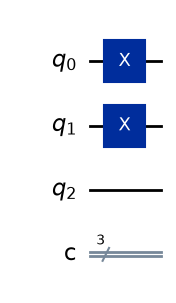


STEP 3: Apply Toffoli (CCNOT)
Target flips only if both controls = 1



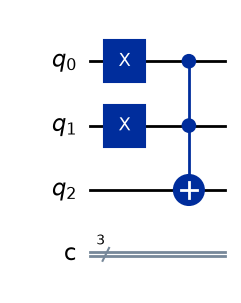


STEP 4: Statevector after Toffoli

Statevector:
Statevector([0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j,
             1.+0.j],
            dims=(2, 2, 2))

STEP 5: Bloch Sphere of Target Qubit (qubit 2)



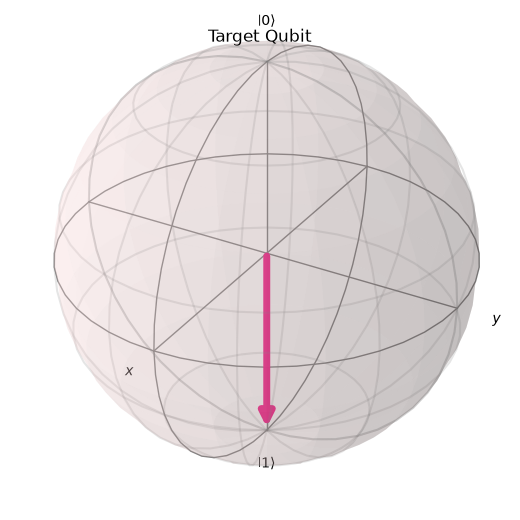


STEP 6: Measurement



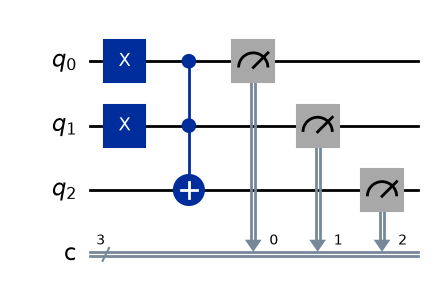


STEP 7: Run Simulation (1024 shots)

Measurement Results:
{'111': 1024}


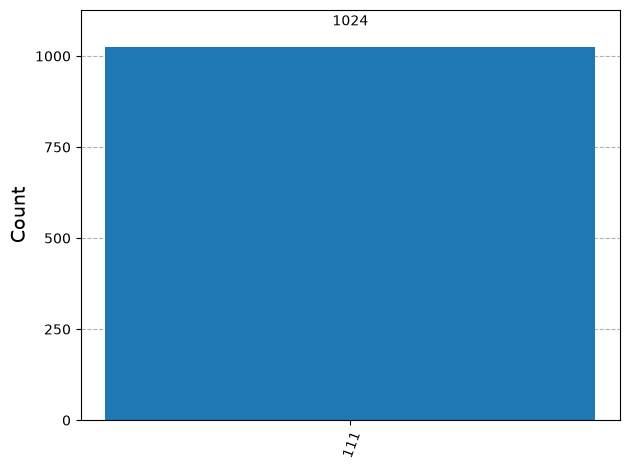


FINAL INTERPRETATION:
Initial state: |110>
Both controls = 1 → target flips
Final state becomes |111>
Measurement yields ~100% |111>
No entanglement is created (pure basis state)


In [1]:
# ============================================================
# FULL Toffoli (CCNOT) Gate Demonstration
# Includes:
#  - Circuit diagram
#  - Statevector
#  - Bloch sphere visualization (target qubit)
#  - Measurement histogram
# ============================================================

%matplotlib inline

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, partial_trace
from qiskit.visualization import plot_histogram, plot_bloch_vector
from matplotlib import pyplot as plt

print("====================================")
print("STEP 1: Create a 3-qubit circuit")
print("Initial state is |000>")
print("====================================\n")

qc = QuantumCircuit(3, 3)
print(qc)

# ------------------------------------------------------------
# STEP 2: Prepare |110>
# ------------------------------------------------------------

print("\n====================================")
print("STEP 2: Prepare state |110>")
print("Apply X to qubit 0 and qubit 1 (controls)")
print("====================================\n")

qc.x(0)
qc.x(1)

qc.draw('mpl')
plt.show()

# ------------------------------------------------------------
# STEP 3: Apply Toffoli gate
# ------------------------------------------------------------

print("\n====================================")
print("STEP 3: Apply Toffoli (CCNOT)")
print("Target flips only if both controls = 1")
print("====================================\n")

qc.ccx(0, 1, 2)

qc.draw('mpl')
plt.show()

# ------------------------------------------------------------
# STEP 4: Show statevector BEFORE measurement
# ------------------------------------------------------------

print("\n====================================")
print("STEP 4: Statevector after Toffoli")
print("====================================\n")

state = Statevector.from_instruction(qc)
print("Statevector:")
print(state)

# ------------------------------------------------------------
# STEP 5: Bloch sphere of target qubit
# ------------------------------------------------------------

print("\n====================================")
print("STEP 5: Bloch Sphere of Target Qubit (qubit 2)")
print("====================================\n")

reduced_target = partial_trace(state, [0,1])

bloch = [
    2 * reduced_target.data[0][1].real,
    -2 * reduced_target.data[0][1].imag,
    reduced_target.data[0][0].real - reduced_target.data[1][1].real
]

plot_bloch_vector(bloch)
plt.title("Target Qubit")
plt.show()

# ------------------------------------------------------------
# STEP 6: Measurement
# ------------------------------------------------------------

print("\n====================================")
print("STEP 6: Measurement")
print("====================================\n")

qc.measure([0,1,2],[0,1,2])
qc.draw('mpl')
plt.show()

# ------------------------------------------------------------
# STEP 7: Simulation
# ------------------------------------------------------------

print("\n====================================")
print("STEP 7: Run Simulation (1024 shots)")
print("====================================\n")

simulator = AerSimulator()
result = simulator.run(qc, shots=1024).result()
counts = result.get_counts()

print("Measurement Results:")
print(counts)

plot_histogram(counts)
plt.show()

print("\n====================================")
print("FINAL INTERPRETATION:")
print("Initial state: |110>")
print("Both controls = 1 → target flips")
print("Final state becomes |111>")
print("Measurement yields ~100% |111>")
print("No entanglement is created (pure basis state)")
print("====================================")